# 강의실 사람 추적 1차 분석

기록된 예비 실험 두 건의 수치를 재집계한다. 입력 수치를 셀에 포함했으며, 그래프 재실행에는 matplotlib가 필요하다.

## 공개 강의실 영상 인원 집계

출처는 저장소 README의 강의실 영상 검증 기록이다. AIRC-SMARTCLASS Part 2의 029.avi 첫 30초 중 세 시점이다. 인원과 박스의 개수 차이는 Precision이나 Recall이 아니다.

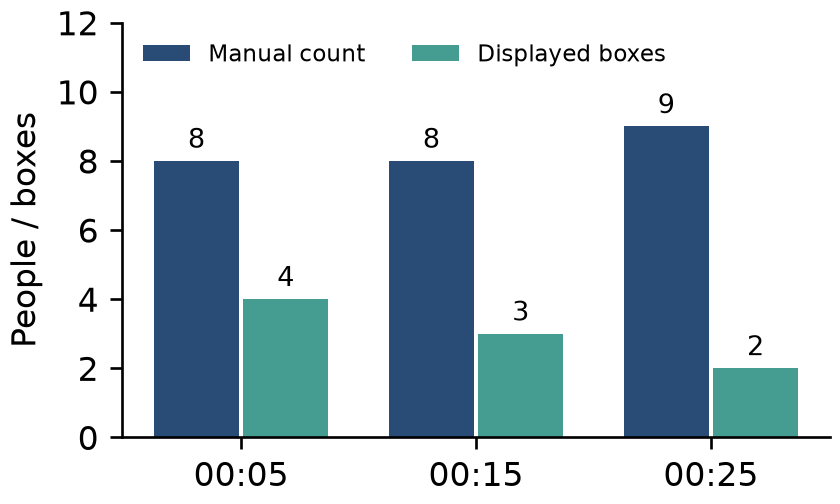

In [1]:
import matplotlib.pyplot as plt

times = ['00:05', '00:15', '00:25']
manual = [8, 8, 9]
boxes = [4, 3, 2]
fig, ax = plt.subplots(figsize=(3.5, 2.1), layout='constrained')
x = range(len(times))
ax.bar([i-.19 for i in x], manual, .36, label='Manual count', color='#284C75')
ax.bar([i+.19 for i in x], boxes, .36, label='Displayed boxes', color='#459C91')
for group in ax.containers:
    ax.bar_label(group, padding=2, fontsize=8)
ax.set_xticks(list(x), times)
ax.set_ylim(0, 12)
ax.set_ylabel('People / boxes')
ax.legend(loc='upper left', ncols=2, fontsize=7, frameon=False)
plt.show()


## AIM 사용 여부와 특징 추출 시간

출처는 outputs/aim-ablation/encoder-benchmark.json이다. 익명화된 데모 이미지의 수동 크롭 4개를 CPU 6스레드로 처리했다. 켬→끔→끔→켬 순서로 실행하고, 구성별 실행당 1회 워밍업 후 측정한 8회 평균을 동일 가중치로 합산했다. 탐지·추적·화면 갱신 소요 시간은 포함하지 않는다.

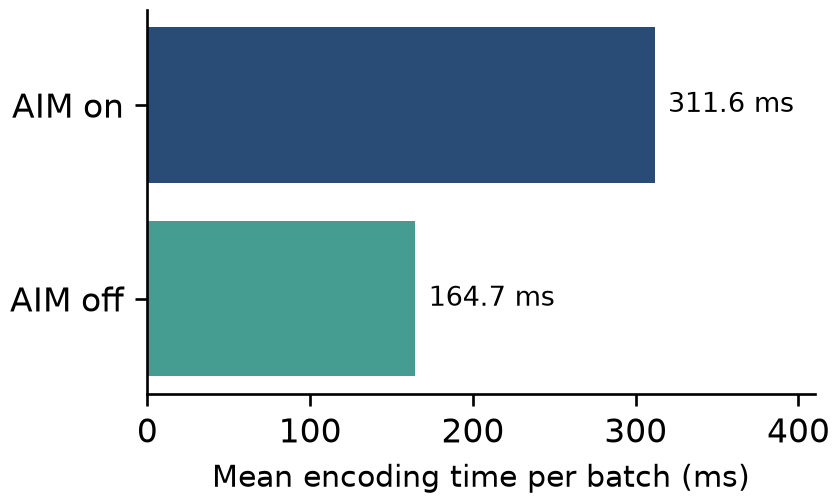

In [2]:
from statistics import mean

runs = [(True, 308.6840883770492), (False, 166.25613023643382), (False, 163.05989075044636), (True, 314.55814048240427)]
on, off = [mean(ms for enabled, ms in runs if enabled == state)
           for state in (True, False)]
reduction = (on-off)/on
fig, ax = plt.subplots(figsize=(3.5, 2.1), layout='constrained')
bars = ax.barh(['AIM off', 'AIM on'], [off, on], color=['#459C91', '#284C75'])
ax.bar_label(bars, fmt='%.1f ms', padding=4, fontsize=8)
ax.set_xlim(0, 410)
ax.set_xlabel('Mean encoding time per batch (ms)', fontsize=9)
plt.show()


## 최종 평가

인물 ID와 박스를 프레임별로 기록한 별도 영상에서 IDF1, HOTA, ID 전환, 재입장 복구율과 실제 FPS를 비교한다. 현재 결과로 최종 모델을 선택할 수 없다.